# Un inicio de transporte óptimo para potenciales moldeados

**Pregunta:** ¿Supera un inicio de transporte óptimo al estado del arte para potenciales moldeados, el MRAF de slmsuite ejecutado sobre el mismo objetivo, con la misma mezcla y el mismo número de iteraciones, y de dónde viene la ganancia?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** notebook 03 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

El notebook anterior dejó a MRAF necesitando un inicio suave, y con la mezcla de 0,4 que se usa aquí deja el disco con un error de 0,1451 tras 30 iteraciones (la celda 8 lo mide más abajo). Una línea reciente de trabajo (Swan et al. 2024, https://arxiv.org/abs/2408.17025) parte MRAF de la fase que daría un mapa de transporte óptimo, la fase que lleva el haz gaussiano a la forma objetivo con el menor desplazamiento de luz. DinHot la implementa como M18, con el solucionador de Sinkhorn separable de Torchylo et al. (2025). Construirás ese inicio, medirás qué es por sí solo, ejecutarás MRAF desde él y desde el inicio de Fresnel, luego ejecutarás el MRAF de slmsuite 0.5.0 sobre el mismo objetivo y compararás, incluido el caso en que a slmsuite se le entrega la fase de transporte óptimo. La última prueba muestra de dónde viene la ganancia.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, los módulos del pipeline por su ruta y la implementación de referencia fijada
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.core import score
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m08_mraf
from pipeline.model.holo.methods.optim import m18_ot_mraf
import slmsuite
from slmsuite.holography.algorithms import Hologram

slmsuite.configure_logging(None)  # sin registro de consola dentro de las salidas

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def shape_numbers(phi, target, setup):
    """Los dos números del producto para una forma: el error (``score.signal_error_pct`` sobre 100) y la
    fracción de la potencia en la región de señal."""
    field = forward.fft_focal_field(phi, setup)
    error = score.signal_error_pct(field, target, setup) / 100.0
    return error, np.sum(np.abs(field[target.mask]) ** 2) / setup.n_pix**2


numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot; slmsuite 0.5.0 es una biblioteca de código abierto para holografía con SLM con licencia MIT (https://pypi.org/project/slmsuite/).
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros; la implementación de referencia se usa como biblioteca bajo su propia licencia.
- Archivo leído: `data/examples/cases.json`, caso C04, un disco de 15 um de radio sobre el SLM de 256 por 256 píxeles; su dispositivo (8 bits, crosstalk de píxeles) no se usa, pues ni M08, ni M18, ni el MRAF de slmsuite lo modelan.

In [2]:
# caso C04: un disco de 15 um de radio, moldeado en el SLM de 256 x 256 píxeles; el dispositivo del caso no se usa aquí
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
target = target_of(rec)
seed = rec["seed"]
mixing = 0.4
print(f"disco de {int((target.amplitude > 0).sum())} bins, región de señal {int(target.mask.sum())} bins")
print(f"mezcla {mixing}")

disco de 2861 bins, región de señal 3389 bins
mezcla 0.4


## Método

Ambos métodos iteran MRAF (Pasienski y DeMarco 2008, https://doi.org/10.1364/OE.16.002176): dentro de la región de señal la amplitud focal se fuerza a $mT$, fuera conserva $(1-m)$ de lo que hizo el holograma. Difieren en la fase de la que parten. M08 parte de una fase de lente de Fresnel. M18 parte de la fase de transporte óptimo. Bajo la aproximación de fase estacionaria la fase $\phi$ del SLM satisface una ecuación de Monge-Ampère, $G^2(\nabla\phi)\det\nabla^2\phi = g^2$, con $g^2$ la intensidad del haz de entrada y $G^2$ la del objetivo; su solución es el mapa de transporte óptimo de costo cuadrático entre ambas, y $\phi$ es la integral de ese mapa (Swan et al. 2024). El mapa se calcula por regularización entrópica, la iteración de Sinkhorn, y Torchylo et al. (2025, https://arxiv.org/abs/2512.19072) muestran que con un costo separable el núcleo se factoriza, de modo que el plan cuesta memoria $O(N)$ y cada actualización es un par de productos de matrices pequeñas. El producto integra el mapa con una solución de Poisson por mínimos cuadrados. Swan et al. informan, en seis objetivos, errores de 1,5 a 3,9 por ciento para MRAF con eficiencia de 18 a 45 por ciento y de 0,17 a 0,96 por ciento con eficiencia de 53 a 85 por ciento desde el inicio de transporte. Las celdas siguientes miden las mismas cantidades en un objetivo.

La referencia de este notebook es el MRAF del producto. La celda ejecuta M08 durante 30 iteraciones con la mezcla de 0,4 que M18 usa por defecto (el extremo superior del rango de 0,30 a 0,40 que dan Pasienski y DeMarco 2008 para MRAF, la elección del producto, registrada en el registro de diseño de M18) y con dos mezclas menores, 0,2 y 0,3, e imprime el error del perfil y la fracción de potencia en la región de señal, como se definieron en el notebook anterior.

In [3]:
# el MRAF del producto (M08, un inicio de lente de Fresnel): la mezcla 0.4 de M18 y dos mezclas menores, 30 iteraciones
budget = Budget(rec["budget"]["iterations"])
mraf_runs = {}
for m in (0.2, 0.3, 0.4):
    mraf_runs[m] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=m)
    err, eff = shape_numbers(mraf_runs[m].phi, target, setup)
    print(f"M08, m = {m}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
res_mraf = mraf_runs[mixing]

M08, m = 0.2: error = 0.0272, fracción de potencia en la señal = 0.0621
M08, m = 0.3: error = 0.0517, fracción de potencia en la señal = 0.1719
M08, m = 0.4: error = 0.1451, fracción de potencia en la señal = 0.3928


Ahora el inicio. La celda calcula la fase de transporte óptimo sola, con la función del producto, y la evalúa como si fuera un holograma. Imprime el residuo de la solución de Sinkhorn, que es cuánto se aparta el plan de tener el haz como marginal, y el ancho del núcleo en bins.

In [4]:
# el inicio de transporte óptimo de M18 solo: el plan de Sinkhorn, su mapa baricéntrico, integrado a una fase
phi_ot, info = m18_ot_mraf.ot_phase(setup, target.amplitude, target.mask)
err, eff = shape_numbers(phi_ot, target, setup)
print(f"fase OT sola, sin iteraciones de MRAF: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
print(f"residuo de Sinkhorn {info['residual']:.2e}, ancho del núcleo {info['sigma_bins']:.2f} bins")

fase OT sola, sin iteraciones de MRAF: error = 0.4294, fracción de potencia en la señal = 0.9933
residuo de Sinkhorn 1.73e-16, ancho del núcleo 16.19 bins


Luego M18: el inicio seguido de 30 iteraciones de MRAF con la misma mezcla. Para ver cómo se mueven los dos métodos, la celda ejecuta además MRAF durante 1, 3 y 10 iteraciones desde el inicio de Fresnel y desde la fase de transporte, e imprime el error de cada una.

In [5]:
# M18: el mismo inicio de TO seguido de 30 iteraciones de MRAF con la misma mezcla, y una serie de presupuestos menores
res_ot = m18_ot_mraf.run(setup, target, budget=budget, rng=Rng(seed), mix=mixing)
err, eff = shape_numbers(res_ot.phi, target, setup)
print(f"M18, m = {mixing}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")
steps = (1, 3, 10, 30)
curve_mraf = [shape_numbers(m08_mraf.run(setup, target, budget=Budget(k), rng=Rng(seed), mixing=mixing).phi,
                            target, setup)[0] for k in steps]
curve_ot = [shape_numbers(m18_ot_mraf.run(setup, target, budget=Budget(k), rng=Rng(seed), mix=mixing, init=phi_ot).phi,
                          target, setup)[0] for k in steps]
print(f"iteraciones de MRAF {steps}")
print("M08", np.round(curve_mraf, 4))
print("M18", np.round(curve_ot, 4))

M18, m = 0.4: error = 0.0275, fracción de potencia en la señal = 0.4446
iteraciones de MRAF (1, 3, 10, 30)
M08 [0.2334 0.2737 0.1862 0.1451]
M18 [0.3552 0.3422 0.136  0.0275]


## Estado del arte

slmsuite es una biblioteca de Python de código abierto para calcular hologramas en SLM, y su MRAF es la referencia para potenciales moldeados que ejecutan quienes usan el campo. En su `Hologram`, la amplitud objetivo es un arreglo sobre la grilla de Fourier con relleno, y un píxel igual a NaN es una región de ruido; la atenuación de la región de ruido es la opción `mraf_factor`. Con la notación de la sección Método, slmsuite conserva la amplitud de señal y multiplica la región de ruido por un factor, que es el $m$ de DinHot y $(1-m)$ dividido por $m$: el factor de este notebook es 1,5. Todo lo demás es el valor por defecto de slmsuite, la ponderación incluida, de modo que la comparación es de la biblioteca tal como la ejecutaría una persona usuaria.

La primera celda de slmsuite ejecuta su MRAF sobre el disco de C04, con la misma región de señal, el mismo haz gaussiano normalizado, el mismo factor, 30 iteraciones, y una fase inicial elegida con el argumento `phase`: primero la fase de Fresnel de M08, luego la fase de transporte óptimo de M18. Imprime los mismos dos números.

In [6]:
# el MRAF de slmsuite sobre el mismo objetivo: región de ruido = NaN, factor de atenuación (1 - m) / m,
# el mismo inicio de Fresnel que M08
x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
goal = np.where(target.mask, target.amplitude, np.nan)
beam = geometry.input_amplitude(setup)
factor = (1 - mixing) / mixing
starts = {"slmsuite, inicio de Fresnel": fresnel, "slmsuite, inicio de TO": phi_ot}
reference = {}
for label, start in starts.items():
    holo = Hologram(goal.copy(), slm_shape=(setup.n_pix, setup.n_pix), amp=beam, phase=start.copy())
    holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
    reference[label] = np.array(holo.get_phase(), dtype=float)
    err, eff = shape_numbers(reference[label], target, setup)
    print(f"{label}: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")

slmsuite, inicio de Fresnel: error = 0.1451, fracción de potencia en la señal = 0.3928
slmsuite, inicio de TO: error = 0.0275, fracción de potencia en la señal = 0.4446


Quien no precondiciona obtiene el inicio propio de slmsuite, una fase aleatoria. La celda ejecuta ese caso, sembrado, e imprime los mismos dos números.

In [7]:
# y slmsuite desde su inicio por defecto, una fase aleatoria, que es lo que obtiene quien lo usa sin preparar el inicio
np.random.seed(seed)
holo = Hologram(goal.copy(), slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
reference["slmsuite, inicio aleatorio"] = np.array(holo.get_phase(), dtype=float)
err, eff = shape_numbers(reference["slmsuite, inicio aleatorio"], target, setup)
print(f"slmsuite, inicio aleatorio: error = {err:.4f}, fracción de potencia en la señal = {eff:.4f}")

slmsuite, inicio aleatorio: error = 0.2940, fracción de potencia en la señal = 0.4236


Todas las corridas en una tabla: los dos métodos del producto y las tres corridas de slmsuite.

In [8]:
# todas las corridas del notebook en una tabla: el mismo objetivo, la misma mezcla, 30 iteraciones
finals = {"M08 (inicio de Fresnel)": res_mraf.phi, "M18 (inicio de TO)": res_ot.phi, **reference}
for label, phi in finals.items():
    err, eff = shape_numbers(phi, target, setup)
    print(f"{label:26s} error = {err:.4f}   potencia en la señal = {eff:.4f}   fuera de ella = {1 - eff:.4f}")

M08 (inicio de Fresnel)    error = 0.1451   potencia en la señal = 0.3928   fuera de ella = 0.6072
M18 (inicio de TO)         error = 0.0275   potencia en la señal = 0.4446   fuera de ella = 0.5554
slmsuite, inicio de Fresnel error = 0.1451   potencia en la señal = 0.3928   fuera de ella = 0.6072
slmsuite, inicio de TO     error = 0.0275   potencia en la señal = 0.4446   fuera de ella = 0.5554
slmsuite, inicio aleatorio error = 0.2940   potencia en la señal = 0.4236   fuera de ella = 0.5764


La primera figura grafica el error de los dos métodos del producto contra el número de iteraciones de MRAF en ejes logarítmicos, para el inicio de Fresnel y para el inicio de transporte óptimo.

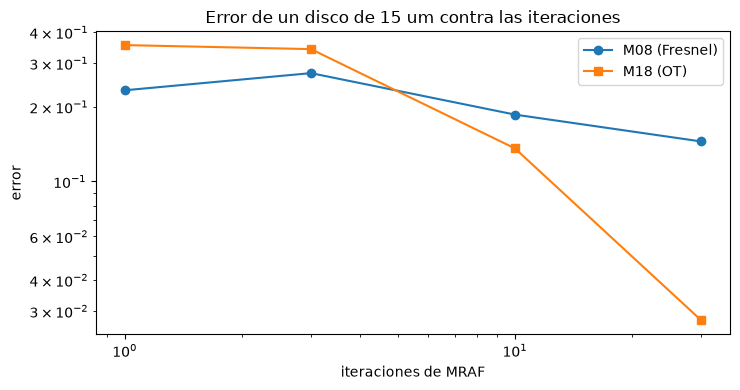

In [9]:
# el error de la forma frente al número de iteraciones de MRAF, M08 y M18, ejes logarítmicos
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.loglog(steps, curve_mraf, "o-", label="M08 (Fresnel)")
ax.loglog(steps, curve_ot, "s-", label="M18 (OT)")
ax.set_xlabel("iteraciones de MRAF")
ax.set_ylabel("error")
ax.set_title("Error de un disco de 15 um contra las iteraciones")
ax.legend()
fig.tight_layout()
plt.show()

Con una y tres iteraciones el inicio de Fresnel va adelante: 0,2334 y 0,2737 frente a 0,3552 y 0,3422, porque la fase de transporte sola tiene un error de 0,4294 y pone 0,9933 de la potencia en la región de señal, como Gerchberg-Saxton, de modo que MRAF tiene que drenarla primero. Con 10 iteraciones el inicio de transporte va adelante, 0,1360 frente a 0,1862, y con 30 es cinco veces menor, 0,0275 frente a 0,1451. La curva de Fresnel no es monótona: sube de 0,2334 con una iteración a 0,2737 con tres. La figura cubre 30 iteraciones; no dice dónde termina ninguna de las curvas, y para eso haría falta una corrida hasta la convergencia.

La segunda figura dibuja la potencia focal a lo largo de la fila por el eje para las cinco corridas, cada una escalada al nivel objetivo dentro del disco, con el objetivo como línea negra punteada. Los dos métodos del producto se dibujan anchos y pálidos, las corridas de slmsuite delgadas y punteadas encima.

M08 (inicio de Fresnel): dentro del disco, de 0.61 a 1.46 del nivel objetivo
M18 (inicio de TO): dentro del disco, de 0.86 a 1.19 del nivel objetivo
slmsuite, inicio de Fresnel: dentro del disco, de 0.61 a 1.46 del nivel objetivo
slmsuite, inicio de TO: dentro del disco, de 0.86 a 1.19 del nivel objetivo
slmsuite, inicio aleatorio: dentro del disco, de 0.26 a 1.44 del nivel objetivo


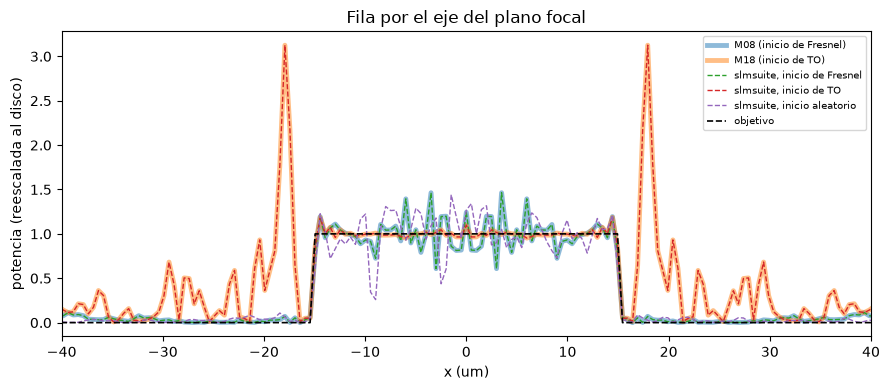

In [10]:
# la potencia focal del disco a lo largo de la fila que pasa por el eje, cada corrida dividida por la potencia pedida en
# el disco
c = setup.n_fft // 2
fig, ax = plt.subplots(figsize=(9, 4))
axis = (np.arange(setup.n_fft) - c) * geometry.focal_bin_m(setup) * 1e6
for label, phi in finals.items():
    row = np.abs(forward.fft_focal_field(phi, setup)[c]) ** 2
    scale = (target.amplitude[c] ** 2).sum() / row[target.amplitude[c] > 0].sum()
    product = label.startswith("M")
    style = dict(ls="-", lw=3.5, alpha=0.5) if product else dict(ls="--", lw=1, alpha=1.0)
    ax.plot(axis, row * scale, label=label, **style)
    inside = target.amplitude[c] > 0
    ratio = (row * scale)[inside] / target.amplitude[c][inside] ** 2
    print(f"{label}: dentro del disco, de {ratio.min():.2f} a {ratio.max():.2f} del nivel objetivo")
ax.plot(axis, target.amplitude[c] ** 2, "k--", lw=1.2, label="objetivo")
ax.set_xlim(-40, 40)
ax.set_xlabel("x (um)")
ax.set_ylabel("potencia (reescalada al disco)")
ax.set_title("Fila por el eje del plano focal")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

Las líneas ancha y delgada del mismo inicio quedan una sobre otra: el MRAF de slmsuite desde la fase de Fresnel es M08, y el MRAF de slmsuite desde la fase de transporte es M18, con la precisión impresa. Dentro del disco el inicio de Fresnel ondula entre 0,61 y 1,46 del nivel objetivo y el inicio aleatorio cae hasta 0,26 de él, mientras el inicio de transporte queda entre 0,86 y 1,19 de él (los rangos impresos). Fuera del disco el inicio de transporte pone picos, de hasta tres veces el nivel objetivo, a ambos lados del borde cerca de 18 um, y otros menores más lejos: es la región de ruido en acción, que guarda cerca de 55 por ciento de la luz, y un potencial que tenga esos picos no es el potencial del disco. El error y la fracción de potencia de este notebook no los penalizan, y la figura muestra una fila de un patrón bidimensional.

## Resultados

**Respuesta:** Con la misma mezcla y el mismo número de iteraciones, sí: desde el inicio de transporte óptimo el error del disco es 0,0275 con 0,4446 de la potencia en la región de señal, frente a 0,1451 con 0,3928 para MRAF desde el inicio de Fresnel, cinco veces menor y con más potencia, y frente a 0,2940 para el MRAF de slmsuite desde su propio inicio aleatorio. M08 llega a un error tan bajo solo con una mezcla menor: 0,0272 con $m = 0,2$, pero con 0,0621 de la potencia, siete veces menos. La ganancia viene del inicio y no del código: slmsuite, al que se le entrega la fase de transporte, da 0,0275 y 0,4446, los números de M18, y con la fase de Fresnel da 0,1451 y 0,3928, los de M08. Los límites son los de un solo objetivo: el error 0,0275 es 2,75 por ciento, sobre el 0,17 a 0,96 por ciento que informan Swan et al. en otros objetivos; las primeras iteraciones son peores que las del inicio de Fresnel; y 0,5554 de la potencia queda fuera de la región de señal.

## Resumen

Un inicio de transporte óptimo es una manera barata de comprar precisión y eficiencia a la vez en MRAF sobre este disco: el inicio solo es un mal holograma, y las iteraciones de MRAF lo convierten luego en uno mejor que los que alcanzan el inicio de Fresnel y el inicio aleatorio en el mismo presupuesto. Los dos métodos MRAF del producto coinciden con los de slmsuite a cuatro dígitos cuando se les da el mismo inicio, lo que respalda la implementación de ambos. Lo que el notebook no muestra es si la ganancia se mantiene en un anillo, una línea o un objetivo de Laguerre-Gauss, si los picos junto al borde son aceptables para un experimento dado, o si la solución de Sinkhorn vale su tiempo en un SLM pequeño.

## Referencias

- Swan, Torchylo, Van de Graaff, Rudolph y Hogan, arXiv 2408.17025 (2024), la inicialización por transporte óptimo de Gerchberg-Saxton y MRAF, https://arxiv.org/abs/2408.17025.
- Torchylo, Swan, Tellez y Hogan, arXiv 2512.19072 (2025), la forma separable de Sinkhorn con memoria lineal, https://arxiv.org/abs/2512.19072.
- Pasienski y DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json y https://pypi.org/project/slmsuite/.